In [ ]:
import os
import pandas as pd
import numpy as np
from dotenv import load_dotenv
from massive import RESTClient

load_dotenv()
API_KEY = os.getenv("MASSIVE_API_KEY")

if API_KEY is None:
    raise ValueError("MASSIVE_API_KEY not found in .env")

client = RESTClient(API_KEY)
print("Client OK")

import sys
print(sys.executable)

Client OK
/Users/onizukalto/ml/bin/python


In [2]:
contracts = []

for i, c in enumerate(client.list_options_contracts(
    underlying_ticker="QQQ",
    limit=1000,
)):
    contracts.append(c)
    if i >= 999:
        break

contracts_df = pd.DataFrame([vars(c) for c in contracts])

print(contracts_df.shape)
print(contracts_df.columns.tolist())
contracts_df.head()

(1000, 11)
['additional_underlyings', 'cfi', 'contract_type', 'correction', 'exercise_style', 'expiration_date', 'primary_exchange', 'shares_per_contract', 'strike_price', 'ticker', 'underlying_ticker']


,additional_underlyings,cfi,contract_type,correction,exercise_style,expiration_date,primary_exchange,shares_per_contract,strike_price,ticker,underlying_ticker
0,None,OCASPS,call,None,american,2026-10-05,BATO,100,450,O:QQQ261005C00450000,QQQ
1,None,OCASPS,call,None,american,2026-10-05,BATO,100,455,O:QQQ261005C00455000,QQQ
2,None,OCASPS,call,None,american,2026-10-05,BATO,100,460,O:QQQ261005C00460000,QQQ
3,None,OCASPS,call,None,american,2026-10-05,BATO,100,465,O:QQQ261005C00465000,QQQ
4,None,OCASPS,call,None,american,2026-10-05,BATO,100,470,O:QQQ261005C00470000,QQQ


In [3]:
print(contracts_df["contract_type"].value_counts())
print("-----------------------------------------")


print(contracts_df["expiration_date"].min(), "→", contracts_df["expiration_date"].max())
print("-----------------------------------------")

print(contracts_df["strike_price"].describe())

contract_type
call    542
put     458
Name: count, dtype: int64
-----------------------------------------
2026-10-05 → 2026-10-08
-----------------------------------------
count    1000.00000
mean      705.17800
std        94.38495
min       450.00000
25%       660.00000
50%       720.00000
75%       759.00000
max       900.00000
Name: strike_price, dtype: float64


In [4]:
DAY = "2026-09-25"   # un vendredi récent, jour de bourse

qqq_bars = pd.DataFrame([
    vars(b) for b in client.list_aggs(
        "QQQ", 1, "minute", DAY, DAY, limit=50000
    )
])

qqq_bars["timestamp"] = (
    pd.to_datetime(qqq_bars["timestamp"], unit="ms", utc=True)
      .dt.tz_convert("America/New_York")
)

print(qqq_bars.shape)
qqq_bars.head()

(898, 9)


,open,high,low,close,volume,vwap,timestamp,transactions,otc
0,744.00,744.76,741.7300,744.050,17301.861672,743.8006,2026-09-25 04:00:00-04:00,630,None
1,744.14,744.91,741.6200,744.070,51161.385225,743.2659,2026-09-25 04:01:00-04:00,1030,None
2,744.48,744.89,743.8200,744.110,50861.000000,744.3381,2026-09-25 04:02:00-04:00,764,None
3,743.94,743.94,743.6100,743.625,5574.086100,743.8088,2026-09-25 04:03:00-04:00,94,None
4,743.63,743.65,743.4725,743.520,1140.977958,744.1871,2026-09-25 04:04:00-04:00,40,None


In [5]:
spot = qqq_bars["open"].iloc[0]   # prix à l'ouverture
print("Spot QQQ à l'ouverture :", spot)

odte = pd.DataFrame([
    vars(c) for c in client.list_options_contracts(
        underlying_ticker="QQQ",
        expiration_date=DAY,
        as_of=DAY,
        expired=True,
        strike_price_gte=spot * 0.98,
        strike_price_lte=spot * 1.02,
        limit=1000,
    )
])

print(odte.shape)
print(odte["contract_type"].value_counts())
odte[["ticker", "contract_type", "strike_price"]].head(10)

Spot QQQ à l'ouverture : 744.0
(58, 11)
contract_type
call    29
put     29
Name: count, dtype: int64


,ticker,contract_type,strike_price
0,O:QQQ260925C00730000,call,730
1,O:QQQ260925C00731000,call,731
2,O:QQQ260925C00732000,call,732
3,O:QQQ260925C00733000,call,733
4,O:QQQ260925C00734000,call,734
5,O:QQQ260925C00735000,call,735
6,O:QQQ260925C00736000,call,736
7,O:QQQ260925C00737000,call,737
8,O:QQQ260925C00738000,call,738
9,O:QQQ260925C00739000,call,739


In [ ]:
test_ticker = odte["ticker"].iloc[len(odte) // 2]   # un contrat au milieu = proche du spot
print(test_ticker)

opt_bars = pd.DataFrame([
    vars(b) for b in client.list_aggs(
        test_ticker, 1, "minute", DAY, DAY, limit=50000
    )
])
opt_bars["timestamp"] = (
    pd.to_datetime(opt_bars["timestamp"], unit="ms", utc=True)
      .dt.tz_convert("America/New_York")
)

print(opt_bars.shape)
opt_bars.head()

OK O:QQQ260925C00730000 168
OK O:QQQ260925C00731000 102
OK O:QQQ260925C00732000 103
OK O:QQQ260925C00733000 112
OK O:QQQ260925C00734000 122
OK O:QQQ260925C00735000 243
OK O:QQQ260925C00736000 207
OK O:QQQ260925C00737000 247
OK O:QQQ260925C00738000 260
OK O:QQQ260925C00739000 294
OK O:QQQ260925C00740000 362
OK O:QQQ260925C00741000 356
OK O:QQQ260925C00742000 385
OK O:QQQ260925C00743000 385
OK O:QQQ260925C00744000 386
OK O:QQQ260925C00745000 386
OK O:QQQ260925C00746000 386
OK O:QQQ260925C00747000 386
OK O:QQQ260925C00748000 386
OK O:QQQ260925C00749000 371
OK O:QQQ260925C00750000 376
OK O:QQQ260925C00751000 309
OK O:QQQ260925C00752000 279
OK O:QQQ260925C00753000 216
OK O:QQQ260925C00754000 178
OK O:QQQ260925C00755000 190
OK O:QQQ260925C00756000 159
OK O:QQQ260925C00757000 155
OK O:QQQ260925C00758000 113
OK O:QQQ260925P00730000 297
OK O:QQQ260925P00731000 233
OK O:QQQ260925P00732000 240
OK O:QQQ260925P00733000 274
OK O:QQQ260925P00734000 294
OK O:QQQ260925P00735000 338
OK O:QQQ260925P00736

In [7]:
qqq_bars = qqq_bars.set_index("timestamp").between_time("09:30", "15:59").reset_index()

spot = qqq_bars["open"].iloc[0]
print("Spot QQQ à 9h30 :", spot)
print(qqq_bars["timestamp"].min(), "→", qqq_bars["timestamp"].max(), "|", len(qqq_bars), "minutes")

Spot QQQ à 9h30 : 742.83
2026-09-25 09:30:00-04:00 → 2026-09-25 15:59:00-04:00 | 390 minutes


In [9]:
#Cellule 8
import time
from pathlib import Path

RAW_DIR = Path("data/raw") / DAY
RAW_DIR.mkdir(parents=True, exist_ok=True)

SLEEP = 13   # pause entre deux requêtes ≈ 5 requêtes/min

for _, row in odte.iterrows():
    path = RAW_DIR / f"{row['ticker'].replace(':', '_')}.parquet"
    if path.exists():                  # déjà téléchargé → on saute
        continue

    # jusqu'à 3 tentatives si l'API répond 429
    for attempt in range(3):
        try:
            bars = pd.DataFrame([
                vars(b) for b in client.list_aggs(row["ticker"], 1, "minute", DAY, DAY, limit=50000)
            ])
            break
        except Exception as e:
            print(f"Limite atteinte sur {row['ticker']}, pause 60 s (tentative {attempt + 1}/3)")
            time.sleep(60)
    else:
        print("Abandon pour", row["ticker"], "- relance la cellule plus tard")
        continue

    bars["ticker"] = row["ticker"]
    bars["contract_type"] = row["contract_type"]
    bars["strike_price"] = row["strike_price"]
    bars.to_parquet(path)              # sauvegardé même si vide
    print("OK", row["ticker"], len(bars))

    time.sleep(SLEEP)

# --- relecture de tous les fichiers ---
files = list(RAW_DIR.glob("*.parquet"))
options_bars = pd.concat([pd.read_parquet(f) for f in files], ignore_index=True)
options_bars = options_bars.dropna(subset=["timestamp"])

options_bars["timestamp"] = (
    pd.to_datetime(options_bars["timestamp"], unit="ms", utc=True)
      .dt.tz_convert("America/New_York")
)

print(options_bars.shape)
print(options_bars["ticker"].nunique(), "contrats avec des données")
options_bars.head()

(14700, 12)
58 contrats avec des données


,open,high,low,close,volume,vwap,timestamp,transactions,otc,ticker,contract_type,strike_price
0,4.22,4.31,3.95,4.16,130,4.0688,2026-09-25 09:30:00-04:00,17,None,O:QQQ260925C00739000,call,739
1,4.02,4.02,3.70,3.88,33,3.9033,2026-09-25 09:32:00-04:00,9,None,O:QQQ260925C00739000,call,739
2,4.60,5.20,4.60,5.20,85,4.8869,2026-09-25 09:34:00-04:00,31,None,O:QQQ260925C00739000,call,739
3,5.25,5.37,5.15,5.20,55,5.2520,2026-09-25 09:36:00-04:00,8,None,O:QQQ260925C00739000,call,739
4,5.21,5.67,5.21,5.43,22,5.5345,2026-09-25 09:38:00-04:00,13,None,O:QQQ260925C00739000,call,739


In [10]:
ecarts = (
    options_bars.sort_values(["ticker", "timestamp"])
    .groupby("ticker")["timestamp"]
    .diff()
    .value_counts()
    .head(10)
)
print(ecarts)

print(options_bars["timestamp"].dt.minute.mod(2).value_counts())

timestamp
0 days 00:01:00    11931
0 days 00:02:00     1596
0 days 00:03:00      374
0 days 00:04:00      232
0 days 00:05:00      134
0 days 00:06:00       74
0 days 00:07:00       64
0 days 00:08:00       50
0 days 00:09:00       35
0 days 00:10:00       25
Name: count, dtype: int64
timestamp
0    7458
1    7242
Name: count, dtype: int64


In [11]:
options_bars["premium"] = options_bars["volume"] * options_bars["vwap"] * 100

flow = options_bars.pivot_table(
    index="timestamp",
    columns="contract_type",
    values=["volume", "premium"],
    aggfunc="sum",
    fill_value=0,
)
flow.columns = [f"{ctype}_{metric}" for metric, ctype in flow.columns]

flow["put_call_volume_ratio"] = flow["put_volume"] / flow["call_volume"].replace(0, np.nan)
flow["net_premium"] = flow["call_premium"] - flow["put_premium"]

print(flow.shape)
flow.head(10)

(405, 6)


,call_premium,put_premium,call_volume,put_volume,put_call_volume_ratio,net_premium
timestamp,,,,,,
2026-09-25 09:30:00-04:00,1870769.42,1512732.81,15332,14182,0.924993,358036.61
2026-09-25 09:31:00-04:00,8200.02,15750.99,10,19,1.900000,-7550.97
2026-09-25 09:32:00-04:00,1361324.87,3424496.16,11218,24194,2.156712,-2063171.29
2026-09-25 09:33:00-04:00,31025.10,1174.00,28,1,0.035714,29851.10
2026-09-25 09:34:00-04:00,3140183.57,1137128.15,23219,10438,0.449546,2003055.42
2026-09-25 09:35:00-04:00,16077.32,6118.99,391,7,0.017903,9958.33
2026-09-25 09:36:00-04:00,2284919.89,777456.87,16860,8216,0.487307,1507463.02
2026-09-25 09:37:00-04:00,10046.21,7254.00,49,11,0.224490,2792.21
2026-09-25 09:38:00-04:00,2259309.73,769225.38,14977,8819,0.588836,1490084.35


In [12]:
HORIZON = 5   # minutes

df = qqq_bars.set_index("timestamp")[["close"]].rename(columns={"close": "price"})

df = df.join(flow, how="left")
flow_cols = ["call_volume", "put_volume", "call_premium", "put_premium", "net_premium"]
df[flow_cols] = df[flow_cols].fillna(0)

df["return_1m"] = df["price"].pct_change(1)
df["return_5m"] = df["price"].pct_change(5)

df["future_price"] = df["price"].shift(-HORIZON)
df["target"] = (df["future_price"] > df["price"]).astype(int)

df = df.dropna(subset=["future_price", "return_5m"])

print(df.shape)
print(df["target"].value_counts(normalize=True))
df.head(10)

(380, 11)
target
1    0.5
0    0.5
Name: proportion, dtype: float64


,price,call_premium,put_premium,call_volume,put_volume,put_call_volume_ratio,net_premium,return_1m,return_5m,future_price,target
timestamp,,,,,,,,,,,
2026-09-25 09:35:00-04:00,743.8650,16077.32,6118.99,391,7,0.017903,9958.33,0.000336,0.001852,744.280,1
2026-09-25 09:36:00-04:00,743.7100,2284919.89,777456.87,16860,8216,0.487307,1507463.02,-0.000208,0.002230,744.425,1
2026-09-25 09:37:00-04:00,743.8300,10046.21,7254.00,49,11,0.224490,2792.21,0.000161,0.001784,744.360,1
2026-09-25 09:38:00-04:00,744.0500,2259309.73,769225.38,14977,8819,0.588836,1490084.35,0.000296,0.001555,743.955,0
2026-09-25 09:39:00-04:00,744.0991,145287.75,23353.56,171,602,3.520468,121934.19,0.000066,0.000651,744.265,1
2026-09-25 09:40:00-04:00,744.2800,1782601.09,660518.11,12369,5992,0.484437,1122082.98,0.000243,0.000558,743.850,0
2026-09-25 09:41:00-04:00,744.4250,2334779.64,667326.33,17440,7929,0.454644,1667453.31,0.000195,0.000961,744.140,0
2026-09-25 09:42:00-04:00,744.3600,29119.96,16905.01,51,25,0.490196,12214.95,-0.000087,0.000713,744.400,1
2026-09-25 09:43:00-04:00,743.9550,1452681.11,924853.78,16742,8093,0.483395,527827.33,-0.000544,-0.000128,743.720,0


In [13]:
check = options_bars.assign(parite=options_bars["timestamp"].dt.minute % 2)

print(check.groupby("parite")["volume"].sum())
print()
print(check.groupby(["ticker", "parite"])["volume"].sum().unstack().head(10))

parite
0    2787637
1    2632430
Name: volume, dtype: int64

parite                   0     1
ticker                          
O:QQQ260925C00730000   491   684
O:QQQ260925C00731000   239   242
O:QQQ260925C00732000   313   235
O:QQQ260925C00733000   721   432
O:QQQ260925C00734000   794  2000
O:QQQ260925C00735000  2069  3520
O:QQQ260925C00736000  1137  1171
O:QQQ260925C00737000  1847  1412
O:QQQ260925C00738000  2669  3356
O:QQQ260925C00739000  5974  4875


In [14]:
WINDOW = 5

for col in ["call_volume", "put_volume", "call_premium", "put_premium"]:
    df[f"{col}_{WINDOW}m"] = df[col].rolling(WINDOW).sum()

df[f"put_call_ratio_{WINDOW}m"] = (
    df[f"put_volume_{WINDOW}m"] / df[f"call_volume_{WINDOW}m"].replace(0, np.nan)
)
df[f"net_premium_{WINDOW}m"] = df[f"call_premium_{WINDOW}m"] - df[f"put_premium_{WINDOW}m"]

df = df.dropna()

print(df.shape)
df.filter(like="_5m").head(10)

(376, 17)


,return_5m,call_volume_5m,put_volume_5m,call_premium_5m,put_premium_5m,put_call_ratio_5m,net_premium_5m
timestamp,,,,,,,
2026-09-25 09:39:00-04:00,0.000651,32448.0,17655.0,4715640.90,1583408.80,0.544101,3132232.10
2026-09-25 09:40:00-04:00,0.000558,44426.0,23640.0,6482164.67,2237807.92,0.532121,4244356.75
2026-09-25 09:41:00-04:00,0.000961,45006.0,23353.0,6532024.42,2127677.38,0.518886,4404347.04
2026-09-25 09:42:00-04:00,0.000713,45008.0,23367.0,6551098.17,2137328.39,0.519174,4413769.78
2026-09-25 09:43:00-04:00,-0.000128,46773.0,22641.0,5744469.55,2292956.79,0.484061,3451512.76
2026-09-25 09:44:00-04:00,0.000223,60183.0,31598.0,7185172.07,3308295.24,0.525032,3876876.83
2026-09-25 09:45:00-04:00,-0.000578,48057.0,26520.0,5497502.08,2759263.07,0.551845,2738239.01
2026-09-25 09:46:00-04:00,-0.000383,40897.0,26403.0,4450079.81,2940212.43,0.645597,1509867.38
2026-09-25 09:47:00-04:00,0.000054,49773.0,33224.0,5611988.08,3687248.93,0.667510,1924739.15


In [25]:
import time
from pathlib import Path

RAW_ROOT = Path("data/raw")
SLEEP = 13            # secondes entre deux requêtes
STRIKE_RANGE = 0.01   # ±2 % autour du spot


def api_call(fn, *args, **kwargs):
    """Appelle l'API, attend ensuite SLEEP secondes, réessaie 3 fois en cas d'erreur."""
    for attempt in range(3):
        try:
            result = [vars(x) for x in fn(*args, **kwargs)]
            time.sleep(SLEEP)
            return result
        except Exception as e:
            print(f"  erreur {e.__class__.__name__}, pause 60 s (tentative {attempt + 1}/3)")
            time.sleep(60)
    raise RuntimeError("API indisponible après 3 tentatives")


def cached(path, fetch):
    """Si le fichier existe, on le relit. Sinon on télécharge et on le sauvegarde."""
    if path.exists():
        return pd.read_parquet(path)
    df = pd.DataFrame(fetch())
    df.to_parquet(path)
    return df


def to_ny(ts):
    return pd.to_datetime(ts, unit="ms", utc=True).dt.tz_convert("America/New_York")

In [53]:
def download_day(day):
    day_dir = RAW_ROOT / day
    day_dir.mkdir(parents=True, exist_ok=True)

    # 1. prix QQQ minute par minute, séance régulière
    qqq = cached(day_dir / "_qqq.parquet",
                 lambda: api_call(client.list_aggs, "QQQ", 1, "minute", day, day, limit=50000))
    qqq["timestamp"] = to_ny(qqq["timestamp"])
    qqq = qqq.set_index("timestamp").between_time("09:30", "15:59").reset_index()
    spot = qqq["open"].iloc[0]

    # 2. contrats 0DTE proches du spot
    contracts = cached(day_dir / "_contracts.parquet",
        lambda: api_call(client.list_options_contracts,
                         underlying_ticker="QQQ", expiration_date=day, as_of=day, expired=True,
                         strike_price_gte=spot * (1 - STRIKE_RANGE),
                         strike_price_lte=spot * (1 + STRIKE_RANGE),
                         limit=1000))

    contracts = contracts[
        contracts["strike_price"].between(spot * (1 - STRIKE_RANGE), spot * (1 + STRIKE_RANGE))
    ]

    # 3. activité de chaque contrat
    all_bars = []
    for _, row in contracts.iterrows():
        bars = cached(day_dir / f"{row['ticker'].replace(':', '_')}.parquet",
                      lambda: api_call(client.list_aggs, row["ticker"], 1, "minute", day, day, limit=50000))
        if bars.empty:
            continue
        bars = bars.assign(ticker=row["ticker"],
                           contract_type=row["contract_type"],
                           strike_price=row["strike_price"])
        all_bars.append(bars)

    if not all_bars:
        print(f"  aucune donnée d'options pour {day}")
        return qqq, None

    options = pd.concat(all_bars, ignore_index=True)
    options["timestamp"] = to_ny(options["timestamp"])
    return qqq, options

In [68]:
def build_features(qqq, options, horizon=5, window=5):
    # flow par minute
    options = options.assign(premium=options["volume"] * options["vwap"] * 100)
    flow = options.pivot_table(index="timestamp", columns="contract_type",
                               values=["volume", "premium"], aggfunc="sum", fill_value=0)
    flow.columns = [f"{ctype}_{metric}" for metric, ctype in flow.columns]
    flow = flow.reindex(columns=["call_volume", "put_volume", "call_premium", "put_premium"],
                        fill_value=0)

    # alignement sur toutes les minutes de séance
    df = qqq.set_index("timestamp")[["close"]].rename(columns={"close": "price"})
    df = df.join(flow, how="left").fillna(0)
    df["net_premium"] = df["call_premium"] - df["put_premium"]

    # features lissées sur la fenêtre
    for col in ["call_volume", "put_volume", "call_premium", "put_premium"]:
        df[f"{col}_{window}m"] = df[col].rolling(window).sum()
    df[f"put_call_ratio_{window}m"] = (
        df[f"put_volume_{window}m"] / df[f"call_volume_{window}m"].replace(0, np.nan)
    )
    df[f"net_premium_{window}m"] = df[f"call_premium_{window}m"] - df[f"put_premium_{window}m"]

    # features relatives, sur plusieurs fenêtres
    for w in [5, 15, 30]:
        call_v = df["call_volume"].rolling(w).sum()
        put_v  = df["put_volume"].rolling(w).sum()
        call_p = df["call_premium"].rolling(w).sum()
        put_p  = df["put_premium"].rolling(w).sum()

        df[f"call_share_vol_{w}m"] = call_v / (call_v + put_v).replace(0, np.nan)
        df[f"net_premium_share_{w}m"] = (call_p - put_p) / (call_p + put_p).replace(0, np.nan)
        df[f"total_volume_{w}m"] = call_v + put_v

    # le volume récent est-il élevé par rapport au reste de la journée ?
    df["volume_vs_day_avg"] = df["total_volume_5m"] / df["total_volume_5m"].expanding().mean()

    # features de marché et de temps (passé uniquement)
    df["return_1m"] = df["price"].pct_change(1)
    df["return_5m"] = df["price"].pct_change(5)
    df["return_15m"] = df["price"].pct_change(15)
    df["minutes_since_open"] = df.index.hour * 60 + df.index.minute - (9 * 60 + 30)

    # target
    df["future_price"] = df["price"].shift(-horizon)
    df["target"] = (df["future_price"] > df["price"]).astype(int)

    return df.dropna()

In [69]:
def get_trading_days(start, end):
    days = pd.DataFrame(api_call(client.list_aggs, "QQQ", 1, "day", start, end))
    return to_ny(days["timestamp"]).dt.strftime("%Y-%m-%d").tolist()


days = get_trading_days("2026-09-01", "2026-09-25")
print(days)

all_days = []
for day in days:
    print(f"=== {day} ===")
    qqq, options = download_day(day)
    if options is None:
        continue
    df_day = build_features(qqq, options)
    df_day["day"] = day
    all_days.append(df_day)

dataset = pd.concat(all_days)

Path("data/processed").mkdir(parents=True, exist_ok=True)
dataset.to_parquet("data/processed/dataset.parquet")

print(dataset.shape)
print(dataset.groupby("day")["target"].agg(["count", "mean"]))

['2026-09-01', '2026-09-02', '2026-09-03', '2026-09-04', '2026-09-08', '2026-09-09', '2026-09-10', '2026-09-11', '2026-09-14', '2026-09-15', '2026-09-16', '2026-09-17', '2026-09-18', '2026-09-21', '2026-09-22', '2026-09-23', '2026-09-24', '2026-09-25']
=== 2026-09-01 ===
=== 2026-09-02 ===
=== 2026-09-03 ===
=== 2026-09-04 ===
=== 2026-09-08 ===
=== 2026-09-09 ===
=== 2026-09-10 ===
=== 2026-09-11 ===
=== 2026-09-14 ===
=== 2026-09-15 ===
=== 2026-09-16 ===
=== 2026-09-17 ===
=== 2026-09-18 ===
=== 2026-09-21 ===
=== 2026-09-22 ===
=== 2026-09-23 ===
=== 2026-09-24 ===
=== 2026-09-25 ===
(6408, 29)
            count      mean
day                        
2026-09-01    356  0.511236
2026-09-02    356  0.514045
2026-09-03    356  0.508427
2026-09-04    356  0.539326
2026-09-08    356  0.466292
2026-09-09    356  0.471910
2026-09-10    356  0.449438
2026-09-11    356  0.474719
2026-09-14    356  0.474719
2026-09-15    356  0.443820
2026-09-16    356  0.438202
2026-09-17    356  0.528090
20

In [70]:
new_cols = ["return_15m", "call_share_vol_30m", "net_premium_share_5m", "volume_vs_day_avg"]
print([c for c in new_cols if c not in dataset.columns])   # doit afficher []
print(dataset.shape)

[]
(6408, 29)


In [71]:
dataset = pd.read_parquet("data/processed/dataset.parquet")

FEATURES = [
    "call_volume", "put_volume", "call_premium", "put_premium", "net_premium",
    "call_volume_5m", "put_volume_5m", "call_premium_5m", "put_premium_5m",
    "put_call_ratio_5m", "net_premium_5m",
    "return_1m", "return_5m", "minutes_since_open",
]

days = sorted(dataset["day"].unique())
train_days, test_days = days[:-1], days[-1:]

train = dataset[dataset["day"].isin(train_days)]
test  = dataset[dataset["day"].isin(test_days)]

X_train, y_train = train[FEATURES], train["target"]
X_test,  y_test  = test[FEATURES],  test["target"]

print("Train :", train_days, X_train.shape)
print("Test  :", test_days,  X_test.shape)

Train : ['2026-09-01', '2026-09-02', '2026-09-03', '2026-09-04', '2026-09-08', '2026-09-09', '2026-09-10', '2026-09-11', '2026-09-14', '2026-09-15', '2026-09-16', '2026-09-17', '2026-09-18', '2026-09-21', '2026-09-22', '2026-09-23', '2026-09-24'] (6052, 14)
Test  : ['2026-09-25'] (356, 14)


In [72]:
from sklearn.metrics import accuracy_score

# baseline 1 : toujours prédire la classe la plus fréquente du train
majority = y_train.mode()[0]
print("Baseline classe majoritaire :", accuracy_score(y_test, [majority] * len(y_test)))

# baseline 2 : momentum — si ça a monté sur 5 min, ça continue
momentum = (X_test["return_5m"] > 0).astype(int)
print("Baseline momentum           :", accuracy_score(y_test, momentum))

Baseline classe majoritaire : 0.5028089887640449
Baseline momentum           : 0.43258426966292135


In [73]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import roc_auc_score

model = RandomForestClassifier(
    n_estimators=300,
    max_depth=5,
    min_samples_leaf=20,
    random_state=42,
    n_jobs=-1,
)
model.fit(X_train, y_train)

proba = model.predict_proba(X_test)[:, 1]
pred = (proba > 0.5).astype(int)

print("Accuracy train :", accuracy_score(y_train, model.predict(X_train)))
print("Accuracy test  :", accuracy_score(y_test, pred))
print("ROC AUC test   :", roc_auc_score(y_test, proba))

Accuracy train : 0.6432584269662921
Accuracy test  : 0.5393258426966292
ROC AUC test   : 0.49932140264495156


In [74]:
pos = proba[y_test.values == 1]
neg = proba[y_test.values == 0]

auc_manuel = ((pos[:, None] > neg[None, :]).mean()
              + 0.5 * (pos[:, None] == neg[None, :]).mean())

print(auc_manuel, roc_auc_score(y_test, proba))

0.49932140264495156 0.49932140264495156


<Axes: title={'center': 'Importance des features'}>

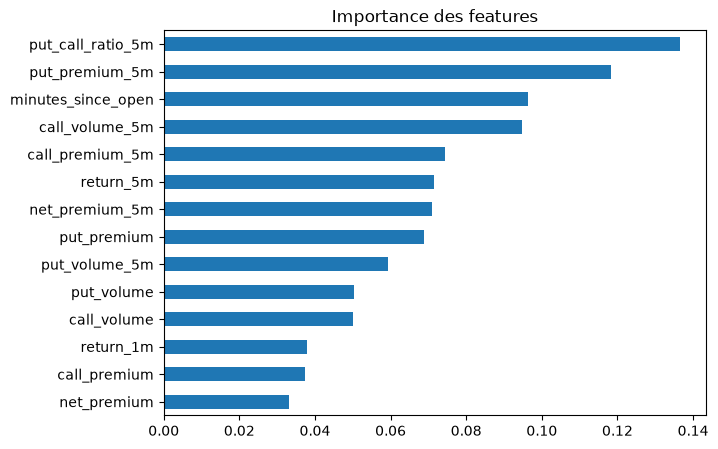

In [75]:
importances = pd.Series(model.feature_importances_, index=FEATURES).sort_values()
importances.plot.barh(figsize=(7, 5), title="Importance des features")

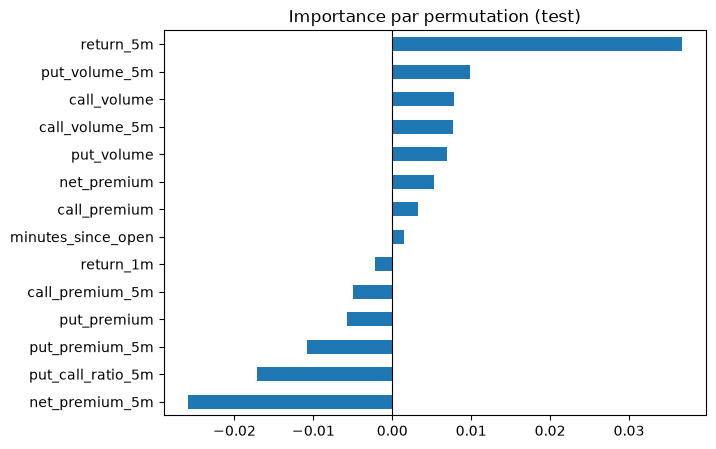

In [76]:
from sklearn.inspection import permutation_importance
from matplotlib import pyplot as plt
perm = permutation_importance(
    model, X_test, y_test,
    scoring="roc_auc",
    n_repeats=30,
    random_state=42,
)

perm_imp = pd.Series(perm.importances_mean, index=FEATURES).sort_values()
perm_imp.plot.barh(figsize=(7, 5), title="Importance par permutation (test)")
plt.axvline(0, color="black", linewidth=0.8)

In [77]:
FEATURES_WF = [f for f in FEATURES if f != "minutes_since_open"]
MIN_TRAIN_DAYS = 5

days = sorted(dataset["day"].unique())
results = []

for i in range(MIN_TRAIN_DAYS, len(days)):
    train = dataset[dataset["day"].isin(days[:i])]
    test  = dataset[dataset["day"] == days[i]]

    model = RandomForestClassifier(
        n_estimators=300, max_depth=5, min_samples_leaf=20,
        random_state=42, n_jobs=-1,
    )
    model.fit(train[FEATURES_WF], train["target"])
    proba = model.predict_proba(test[FEATURES_WF])[:, 1]

    momentum_inv = (test["return_5m"] < 0).astype(int)

    results.append({
        "test_day": days[i],
        "auc": roc_auc_score(test["target"], proba),
        "acc_model": accuracy_score(test["target"], (proba > 0.5).astype(int)),
        "acc_momentum_inv": accuracy_score(test["target"], momentum_inv),
    })

results = pd.DataFrame(results)
print(results)
print()
print(results[["auc", "acc_model", "acc_momentum_inv"]].agg(["mean", "std"]))

      test_day       auc  acc_model  acc_momentum_inv
0   2026-09-09  0.467990   0.446629          0.505618
1   2026-09-10  0.409375   0.443820          0.578652
2   2026-09-11  0.528462   0.511236          0.497191
3   2026-09-14  0.579059   0.556180          0.463483
4   2026-09-15  0.561373   0.494382          0.550562
5   2026-09-16  0.473301   0.508427          0.536517
6   2026-09-17  0.503863   0.497191          0.592697
7   2026-09-18  0.488590   0.471910          0.544944
8   2026-09-21  0.549007   0.382022          0.435393
9   2026-09-22  0.459252   0.488764          0.508427
10  2026-09-23  0.444793   0.432584          0.511236
11  2026-09-24  0.592361   0.544944          0.556180
12  2026-09-25  0.492094   0.497191          0.564607

           auc  acc_model  acc_momentum_inv
mean  0.503809   0.482714          0.526577
std   0.055104   0.047364          0.045259


In [78]:
def walk_forward(dataset, features, min_train_days=5):
    days = sorted(dataset["day"].unique())
    aucs = {}
    for i in range(min_train_days, len(days)):
        train = dataset[dataset["day"].isin(days[:i])]
        test  = dataset[dataset["day"] == days[i]]
        model = RandomForestClassifier(
            n_estimators=300, max_depth=5, min_samples_leaf=20,
            random_state=42, n_jobs=-1,
        )
        model.fit(train[features], train["target"])
        aucs[days[i]] = roc_auc_score(test["target"], model.predict_proba(test[features])[:, 1])
    return pd.Series(aucs)


PRICE = ["return_1m", "return_5m", "return_15m"]
FLOW = [f"{name}_{w}m" for w in [5, 15, 30]
        for name in ["call_share_vol", "net_premium_share", "total_volume"]] + ["volume_vs_day_avg"]

res = pd.DataFrame({
    "prix seul":   walk_forward(dataset, PRICE),
    "flow seul":   walk_forward(dataset, FLOW),
    "prix + flow": walk_forward(dataset, PRICE + FLOW),
})

print(res.round(3))
print()
print(res.agg(["mean", "std"]).round(3))

gain = res["prix + flow"] - res["prix seul"]
print(f"\nApport du flow : {gain.mean():+.3f} ± {gain.std() / np.sqrt(len(gain)):.3f}")

            prix seul  flow seul  prix + flow
2026-09-09      0.437      0.496        0.496
2026-09-10      0.450      0.502        0.479
2026-09-11      0.515      0.513        0.505
2026-09-14      0.526      0.591        0.588
2026-09-15      0.490      0.518        0.561
2026-09-16      0.482      0.468        0.484
2026-09-17      0.538      0.514        0.539
2026-09-18      0.522      0.368        0.401
2026-09-21      0.431      0.548        0.546
2026-09-22      0.513      0.478        0.479
2026-09-23      0.542      0.595        0.618
2026-09-24      0.483      0.581        0.573
2026-09-25      0.460      0.465        0.477

      prix seul  flow seul  prix + flow
mean      0.491      0.511        0.519
std       0.038      0.062        0.059

Apport du flow : +0.027 ± 0.017
